# 국내ETF마스터(PREF01N001) EDA

**데이터셋**: `PREF01N001_국내ETF마스터`
**최종 추출일자(스키마 기준)**: 2026-07-11
**목적**: 국내 상장 ETF 마스터 데이터의 구조, 결측/이상치, 가격·수익률·추적오차·괴리율·거래량 특성을 탐색

> ⚠️ 이 노트북은 **골격(skeleton)** 입니다. 아래 `DATA_PATH`와 데이터 로딩 셀만 각자 환경에 맞게 수정하면 바로 실행할 수 있도록 구성했습니다.
> 컬럼 구성은 제공받은 스키마 파일(73개 컬럼) 기준으로 작성했습니다. 국내채권마스터·공모펀드마스터 노트북과 팔레트·전체 흐름은 통일하되, ETF 특성(시세·추적오차·괴리율·거래량·갱신주기)에 맞는 섹션으로 새로 구성했습니다.

## 컬럼 개요 (스키마 기준, 73개 컬럼)

이 스키마는 컬럼명 접두사가 **갱신 주기**를 나타냅니다 — 이후 EDA에서 갱신주기별로 결측 패턴을 비교할 때 이 구분을 그대로 사용합니다.

| 접두사 | 의미(추정) | 예시 |
|---|---|---|
| `pd_` | 상품 마스터(정적/저빈도 변경) | pd_itm_no, pd_nm, pd_risk_nm |
| `cu_` | 수시 갱신(이벤트 발생 시) | cu_charge_rt, cu_fund_mgmt_co |
| `du_` | 일별 갱신 | du_bpr, du_er_1d, du_vol_1d |
| `wu_` | 주간 갱신 | wu_inv_ast_type, wu_core_yn |
| `nru_` | 준실시간(장중) 갱신 | nru_mkt_diff_rt, nru_mkt_inav |
| `ru_` | 실시간 갱신 | ru_mkt_price, ru_mkt_volume |

| 그룹 | 컬럼 |
|---|---|
| 식별 | pd_itm_no(PK 표기), pd_itm_no_ma(PK 표기), pd_exg_mkt_cd(PK 표기), pd_abrv_nm, pd_nm |
| 분류(범주형) | pd_exg_mkt_nm, pd_grp_no, pd_mkt_id, pd_mkt_nm, pd_curr_cd, pd_curr_nm, pd_sect_cd, pd_sect_nm, pd_risk_cd, pd_risk_nm, pd_pen_risk_nm, wu_inv_ast_type, wu_inv_rgn, cu_strtegy, cu_fund_mgmt_co, cu_base_index, cu_lev_fector, pd_dvid_cycl |
| Y/N 플래그 | pd_pen_tr_yn, pd_sale_yn, pd_spac_yn, pd_tr_yn, wu_core_yn |
| 수수료(텍스트 타입) | cu_charge_rt, cu_charge_etc_rt |
| 날짜 | pd_lste_dt, pd_lstg_dt, du_upt_dt, cu_upt_dt, wu_upt_dt |
| 가격/시세 | du_bpr, du_clpr, du_hpr, du_lpr, du_last_nav, du_nav_yday, du_nav_rnf_amt, ru_mkt_price, pd_lst_price |
| 수익률 | du_er_1d, du_er_1m, du_er_3m, du_er_6m, du_er_1y, du_er_ytd |
| 추적오차·괴리율 | du_chas_errt, du_diff_rt, nru_mkt_diff_rt, nru_mkt_inav |
| 거래량·거래대금 | du_vol_1d, du_vol_avg_1m, du_vol_avg_5d, du_val_1d, du_val_1m, du_val_5d, ru_mkt_volume |
| 규모(AUM/주식수) | du_last_aum, pd_net_tamt, pd_circ_net_tamt, pd_circ_stk_cnt, pd_lst_stk_cnt, pd_stk_cnt |
| 주당지표 | pd_nav_pshr, pd_net_ast_pshr, pd_net_prft_pshr, pd_net_rt_ast_pshr, pd_divd_amt_pshr, pd_dvid_yield |

**스키마에서 미리 확인해둘 이슈 4가지** (국내채권마스터·공모펀드마스터 EDA에서 배운 패턴을 미리 반영):

1. **PK 3중 표기**: `pd_exg_mkt_cd`, `pd_itm_no`, `pd_itm_no_ma` 세 컬럼이 모두 PK로 표기되어 있습니다(공모펀드마스터와 동일한 패턴). `pd_itm_no`(상품번호)가 실제 PK일 가능성이 높지만 6번 섹션에서 셋 다 개별 검증합니다.
2. **날짜 sentinel 값**: `pd_lste_dt`(상품거래종료일자) 예시값이 `99991231`입니다 — 이는 결측이 아니라 **"아직 상장폐지 예정 없음"을 뜻하는 의도된 sentinel**로 보입니다. 일반 날짜로 파싱하면 안 되고 별도 플래그로 처리해야 합니다.
3. **타입 불일치 의심**: `du_upt_dt`는 스키마상 `timestamp without time zone`인데 예시값은 `'20260225'`(YYYYMMDD 문자열)입니다. 실제 시간 정보가 있는지 raw 데이터로 확인이 필요합니다.
4. **수수료 컬럼이 text 타입**: `cu_charge_rt`(총보수요율), `cu_charge_etc_rt`(기타비용요율)가 숫자가 아니라 text로 정의되어 있습니다 — 단위 기호(%)가 섞여 있거나 포맷이 일정하지 않을 가능성이 있어 8번 섹션에서 별도로 파싱을 검증합니다.

## 1. 라이브러리 임포트 및 환경 설정

In [1]:
import warnings
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

%matplotlib inline


In [2]:
# --- 차트 스타일 (색상 시스템: 고정 순서 카테고리 팔레트) -------------------
# 국내채권마스터·공모펀드마스터 EDA 노트북과 동일한 팔레트를 재사용해 형식을 통일합니다.
CAT_COLORS = [
    "#2a78d6",  # 1 blue
    "#eb6834",  # 2 orange
    "#1baf7a",  # 3 aqua
    "#eda100",  # 4 yellow
    "#e87ba4",  # 5 magenta
    "#008300",  # 6 green
    "#4a3aa7",  # 7 violet
    "#e34948",  # 8 red
]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_BLUE_CMAP = sns.blend_palette(SEQ_BLUE, as_cmap=True)
DIVERGING_CMAP = sns.diverging_palette(220, 10, s=75, l=50, sep=10, as_cmap=True)  # blue-gray-red

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRIDLINE,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})


def cat_colors(n: int) -> list:
    '''카테고리 개수만큼 고정 순서 팔레트에서 색을 가져온다. 8개 초과 시 top-N + "기타"로 묶는 것을 권장.'''
    if n <= len(CAT_COLORS):
        return CAT_COLORS[:n]
    reps = (n // len(CAT_COLORS)) + 1
    return (CAT_COLORS * reps)[:n]


## 2. 데이터 로드

`DATA_PATH`만 실제 파일 경로로 바꿔서 사용하세요. csv / parquet / xlsx 로더를 모두 준비해뒀고,
`DATA_PATH`의 확장자에 따라 자동으로 분기합니다.

In [3]:
# TODO: 실제 데이터 경로로 수정
DATA_PATH = Path("../perprocessed_datas/v4/PREF01N001_국내ETF마스터_20260711_datarows.xlsx")

# 스키마 기준 컬럼 순서 (raw 데이터 컬럼명이 다르면 여기만 맞춰서 조정)
SCHEMA_COLUMNS = [
    "pd_itm_no", "pd_itm_no_ma", "pd_exg_mkt_cd", "pd_abrv_nm", "pd_nm",
    "pd_exg_mkt_nm", "pd_grp_no", "pd_mkt_id", "pd_mkt_nm", "pd_curr_cd", "pd_curr_nm",
    "pd_sect_cd", "pd_sect_nm", "pd_risk_cd", "pd_risk_nm", "pd_pen_risk_nm",
    "wu_inv_ast_type", "wu_inv_rgn", "cu_strtegy", "cu_fund_mgmt_co", "cu_base_index",
    "cu_lev_fector", "pd_dvid_cycl",
    "pd_pen_tr_yn", "pd_sale_yn", "pd_spac_yn", "pd_tr_yn", "wu_core_yn",
    "cu_charge_rt", "cu_charge_etc_rt",
    "pd_lste_dt", "pd_lstg_dt", "du_upt_dt", "cu_upt_dt", "wu_upt_dt",
    "du_bpr", "du_clpr", "du_hpr", "du_lpr", "du_last_nav", "du_nav_yday",
    "du_nav_rnf_amt", "ru_mkt_price", "pd_lst_price",
    "du_er_1d", "du_er_1m", "du_er_3m", "du_er_6m", "du_er_1y", "du_er_ytd",
    "du_chas_errt", "du_diff_rt", "nru_mkt_diff_rt", "nru_mkt_inav",
    "du_vol_1d", "du_vol_avg_1m", "du_vol_avg_5d", "du_val_1d", "du_val_1m", "du_val_5d",
    "ru_mkt_volume",
    "du_last_aum", "pd_net_tamt", "pd_circ_net_tamt", "pd_circ_stk_cnt",
    "pd_lst_stk_cnt", "pd_stk_cnt",
    "pd_nav_pshr", "pd_net_ast_pshr", "pd_net_prft_pshr", "pd_net_rt_ast_pshr",
    "pd_divd_amt_pshr", "pd_dvid_yield",
]


def load_etf_master(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in (".parquet", ".pq"):
        return pd.read_parquet(path)
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(path)
    raise ValueError(f"지원하지 않는 확장자입니다: {suffix}")


df_raw = load_etf_master(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols")
df_raw.head()


Loaded: 1,734 rows x 67 cols


,cu_base_index,cu_charge_etc_rt,cu_charge_rt,cu_fund_mgmt_co,cu_lev_fector,cu_strtegy,cu_upt_dt,du_bpr,du_chas_errt,du_clpr,du_diff_rt,du_er_1d,du_er_1m,du_er_1y,du_er_3m,du_er_6m,du_er_ytd,du_hpr,du_last_aum,du_last_nav,du_lpr,du_nav_rnf_amt,du_nav_yday,du_upt_dt,du_val_1d,du_val_1m,du_val_5d,du_vol_1d,du_vol_avg_1m,du_vol_avg_5d,pd_abrv_nm,pd_circ_net_tamt,pd_circ_stk_cnt,pd_curr_cd,pd_curr_nm,pd_divd_amt_pshr,pd_dvid_yield,pd_exg_mkt_cd,pd_exg_mkt_nm,pd_grp_no,pd_itm_no,pd_itm_no_ma,pd_lst_price,pd_lst_stk_cnt,pd_lste_dt,pd_lstg_dt,pd_mkt_id,pd_mkt_nm,pd_nav_pshr,pd_net_ast_pshr,pd_net_prft_pshr,pd_net_rt_ast_pshr,pd_net_tamt,pd_nm,pd_pen_risk_nm,pd_pen_tr_yn,pd_risk_cd,pd_risk_nm,pd_sale_yn,pd_sect_cd,pd_spac_yn,pd_stk_cnt,pd_tr_yn,wu_core_yn,wu_inv_ast_type,wu_inv_rgn,wu_upt_dt
0,NaN,0.0000,NaN,미래에셋,1.0000,실물복제,2026-06-15,"13,675.0000",0.0000,"13,615.0000",0.0000,-0.4400,1.3800,11.1400,0.6300,1.7200,3.5400,"13,650.0000","239,236,725,000.0000","13,670.6700","13,560.0000","-13,670.6700","13,670.6700",2026-06-15,"1,127,563,999.0000","1,481,358,349.1000","1,168,756,083.2000","82,836.0000","109,219.7500","85,775.6000",TIGER 미국채10년선물,"239,312,500,000.0000","17,500,000.0000",CURR_CD_KRW,한국원화,0.0000,0.0000,EXG_MKT_NO_001,유가증권,ETF,KR7305080004,A305080,0,17500000,9999-12-31,2018-08-30,STK,유가증권,"13,670.6700",0.0000,0.0000,0.0000,"239,236,722,747.0000",미래에셋 TIGER 미국채10년선물증권상장지수투자신탁(채권-파생형),N,N,PD_RISK_GCD_14,보통위험(4등급),Y,2.0000,N,"17,500,000.0000",N,N,채권,미국,2026-06-15
1,NaN,0.0000,NaN,키움증권(주),1.0000,C,2026-06-15,"7,990.0000",0.0000,"8,160.0000",0.0000,2.1300,-13.7900,-13.5600,-29.3200,-27.7900,-26.6500,"8,230.0000",0.0000,"8,145.3400","8,095.0000",176.0000,"7,969.3400",2026-06-15,"3,605,210.0000","16,201,691.2500","16,536,908.0000",443.0000,"1,998.0500","2,086.8000",키움 바이오TOP10 ETN,0.0000,0.0000,CURR_CD_KRW,한국원화,0.0000,0.0000,EXG_MKT_NO_001,유가증권,ETN,KRG760000148,Q760014,0,700000,9999-12-31,2024-11-08,STK,유가증권,"8,145.3400",0.0000,0.0000,0.0000,"5,578,538,000.0000",키움증권 키움 바이오TOP10 상장지수증권 제14호,N,N,PD_RISK_GCD_11,매우높은위험(1등급),Y,3.0000,N,"700,000.0000",N,N,주식,국내,2026-06-15
2,NaN,0.0000,NaN,미래에셋,1.0000,실물복제,2026-06-15,"7,860.0000",0.0000,"7,865.0000",0.0000,0.0600,-2.6600,-0.1900,-4.0900,-12.6100,-11.7800,"7,935.0000","708,124,075,500.0000","7,777.3100","7,795.0000","-7,777.3100","7,777.3100",2026-06-15,"6,268,212,166.0000","9,504,943,879.9500","5,828,427,296.4000","797,435.0000","1,174,539.1000","741,412.4000",TIGER 차이나항셍테크,"715,653,000,000.0000","91,050,000.0000",CURR_CD_KRW,한국원화,0.0000,0.0000,EXG_MKT_NO_001,유가증권,ETF,KR7371160003,A371160,0,90400000,9999-12-31,2020-12-16,STK,유가증권,"7,777.3100",0.0000,0.0000,0.0000,"701,512,924,330.0000",미래에셋 TIGER 차이나항셍테크증권상장지수투자신탁(주식),위험자산,Y,PD_RISK_GCD_11,매우높은위험(1등급),Y,2.0000,N,"90,750,000.0000",N,N,주식,중국,2026-06-15
3,NaN,0.0000,NaN,NH-Amundi,1.0000,실물복제,2026-06-15,"20,950.0000",0.0000,"21,105.0000",0.0000,0.7400,1.4400,38.3000,13.3800,12.7400,13.9900,"21,190.0000","16,744,960,000.0000","20,931.2000","20,960.0000","-20,931.2000","20,931.2000",2026-06-15,"198,043,874.0000","160,335,035.5500","182,147,473.8000","9,408.0000","7,601.3000","8,717.2000",HANARO 미국S&P500,"16,760,000,000.0000","800,000.0000",CURR_CD_KRW,한국원화,0.0000,0.0000,EXG_MKT_NO_001,유가증권,ETF,KR7432840007,A432840,0,800000,9999-12-31,2022-06-08,STK,유가증권,"20,931.2000",0.0000,0.0000,0.0000,"16,744,962,286.0000",NH-Amundi HANARO 미국S&P500증권상장지수투자신탁(주식),위험자산,Y,PD_RISK_GCD_12,높은위험(2등급),Y,2.0000,N,"800,000.0000",N,Y,주식,미국,2026-06-15
4,NaN,0.0000,NaN,삼성,1.0000,실물복제,2026-06-15,"96,455.0000",0.0000,"101,575.0000",0.0000,5.3100,16.2900,327.9500,71.8300,153.2400,135.8900,"102,590.0000","1,870,904,184,000.0000","96,438.3600","100,195.0000","-96,438.3600","96,438.3600",2026-06-15,"101,589,995,922.0000","24,450,986,246.7500","32,525,435,043.2000","1,004,021.0000","253,578.4000","328,053.0000",KODEX Top5PlusTR,0.0000,"19,400,000.0000",CURR_CD_KRW,한국원화,0.0000,0.0000,EXG_MKT_NO_001,유가증권,ETF,KR7315930008,A315930,0,19400000,9999-12-31,2019-01-22,STK,유가증권,"96,438.36

In [4]:
df = df_raw.copy()

# 컬럼명이 스키마와 대소문자만 다른 경우 등을 대비한 정규화 (필요 없으면 스킵해도 무방)
df.columns = [c.strip() for c in df.columns]

missing_from_schema = [c for c in SCHEMA_COLUMNS if c not in df.columns]
extra_in_data = [c for c in df.columns if c not in SCHEMA_COLUMNS]
print("스키마에는 있는데 데이터에 없는 컬럼:", missing_from_schema)
print("데이터에는 있는데 스키마에 없는 컬럼:", extra_in_data)


스키마에는 있는데 데이터에 없는 컬럼: ['pd_sect_nm', 'pd_dvid_cycl', 'ru_mkt_price', 'nru_mkt_diff_rt', 'nru_mkt_inav', 'ru_mkt_volume']
데이터에는 있는데 스키마에 없는 컬럼: []


## 3. 기본 정보 확인

In [5]:
print(f"shape: {df.shape}")
df.info()


shape: (1734, 67)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1734 entries, 0 to 1733
Data columns (total 67 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cu_base_index       58 non-null     object 
 1   cu_charge_etc_rt    1553 non-null   float64
 2   cu_charge_rt        217 non-null    float64
 3   cu_fund_mgmt_co     1733 non-null   object 
 4   cu_lev_fector       1551 non-null   float64
 5   cu_strtegy          1579 non-null   object 
 6   cu_upt_dt           1551 non-null   object 
 7   du_bpr              1729 non-null   float64
 8   du_chas_errt        1551 non-null   float64
 9   du_clpr             1729 non-null   float64
 10  du_diff_rt          1517 non-null   float64
 11  du_er_1d            1562 non-null   float64
 12  du_er_1m            1540 non-null   float64
 13  du_er_1y            1377 non-null   float64
 14  du_er_3m            1505 non-null   float64
 15  du_er_6m            1476 non-null   f

In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cu_base_index,58,19,종합채권 3개월~1년,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_charge_etc_rt,"1,553.0000",NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
cu_charge_rt,217.0000,NaN,NaN,NaN,0.1242,0.2007,0.0000,0.0000,0.0000,0.3500,0.6400
cu_fund_mgmt_co,1733,96,삼성,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_lev_fector,"1,551.0000",NaN,NaN,NaN,0.8253,0.9867,-3.0000,1.0000,1.0000,1.0000,3.0000
...,...,...,...,...,...,...,...,...,...,...,...
pd_tr_yn,1733,2,N,1661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wu_core_yn,1734,2,N,1646,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wu_inv_ast_type,1734,8,주식,1069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wu_inv_rgn,1734,11,국내,1036,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. 컬럼 그룹 정의

인트로의 표를 그대로 코드로 옮깁니다. 실제 데이터 컬럼 구성이 스키마와 다르면 여기만 수정하면 됩니다.

In [7]:
ID_COLS = ["pd_itm_no", "pd_itm_no_ma", "pd_exg_mkt_cd", "pd_abrv_nm", "pd_nm"]

CATEGORY_COLS = [
    "pd_exg_mkt_nm", "pd_grp_no", "pd_mkt_id", "pd_mkt_nm", "pd_curr_cd", "pd_curr_nm",
    "pd_sect_cd", "pd_sect_nm", "pd_risk_cd", "pd_risk_nm", "pd_pen_risk_nm",
    "wu_inv_ast_type", "wu_inv_rgn", "cu_strtegy", "cu_fund_mgmt_co", "cu_base_index",
    "cu_lev_fector", "pd_dvid_cycl",
]

FLAG_COLS = ["pd_pen_tr_yn", "pd_sale_yn", "pd_spac_yn", "pd_tr_yn", "wu_core_yn"]

FEE_COLS = ["cu_charge_rt", "cu_charge_etc_rt"]  # 스키마상 text 타입 — 8번 섹션에서 숫자 파싱

DATE_COLS = ["pd_lste_dt", "pd_lstg_dt", "du_upt_dt", "cu_upt_dt", "wu_upt_dt"]

PRICE_COLS = [
    "du_bpr", "du_clpr", "du_hpr", "du_lpr", "du_last_nav", "du_nav_yday",
    "du_nav_rnf_amt", "ru_mkt_price", "pd_lst_price",
]

RETURN_COLS = ["du_er_1d", "du_er_1m", "du_er_3m", "du_er_6m", "du_er_1y", "du_er_ytd"]

TRACKING_COLS = ["du_chas_errt", "du_diff_rt", "nru_mkt_diff_rt", "nru_mkt_inav"]

VOLUME_COLS = [
    "du_vol_1d", "du_vol_avg_1m", "du_vol_avg_5d", "du_val_1d", "du_val_1m", "du_val_5d",
    "ru_mkt_volume",
]

SIZE_COLS = [
    "du_last_aum", "pd_net_tamt", "pd_circ_net_tamt", "pd_circ_stk_cnt",
    "pd_lst_stk_cnt", "pd_stk_cnt",
]

PERSHARE_COLS = [
    "pd_nav_pshr", "pd_net_ast_pshr", "pd_net_prft_pshr", "pd_net_rt_ast_pshr",
    "pd_divd_amt_pshr", "pd_dvid_yield",
]

NUMERIC_COLS = PRICE_COLS + RETURN_COLS + TRACKING_COLS + VOLUME_COLS + SIZE_COLS + PERSHARE_COLS

# 실제 데이터에 존재하는 컬럼만 남기기
for _name in ["ID_COLS", "CATEGORY_COLS", "FLAG_COLS", "FEE_COLS", "DATE_COLS", "NUMERIC_COLS"]:
    globals()[_name] = [c for c in globals()[_name] if c in df.columns]

print(f"수치형 {len(NUMERIC_COLS)}개, 범주형 {len(CATEGORY_COLS)}개, 플래그 {len(FLAG_COLS)}개, "
      f"수수료(텍스트) {len(FEE_COLS)}개, 날짜 {len(DATE_COLS)}개, 식별 {len(ID_COLS)}개")


수치형 34개, 범주형 16개, 플래그 5개, 수수료(텍스트) 2개, 날짜 5개, 식별 5개


## 5. 결측치 분석

In [8]:
missing = (
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
missing[missing["missing_count"] > 0]


,missing_count,missing_pct
cu_base_index,1676,96.6600
cu_charge_rt,1517,87.4900
du_er_1y,357,20.5900
du_last_aum,281,16.2100
du_er_6m,258,14.8800
du_er_ytd,257,14.8200
du_er_3m,229,13.2100
du_diff_rt,217,12.5100
du_upt_dt,217,12.5100
du_nav_yday,217,12.5100


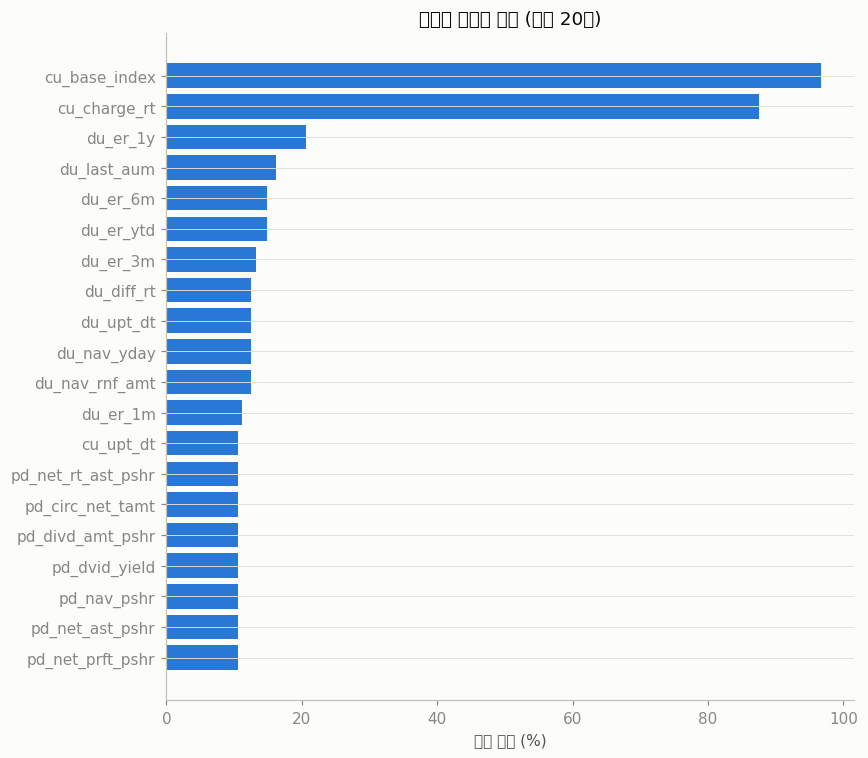

In [9]:
miss_top = missing[missing["missing_count"] > 0].head(20)
if len(miss_top):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(miss_top))))
    ax.barh(miss_top.index[::-1], miss_top["missing_pct"][::-1], color=CAT_COLORS[0])
    ax.set_xlabel("결측 비율 (%)")
    ax.set_title("컬럼별 결측치 비율 (상위 20개)")
    plt.tight_layout()
    plt.show()
else:
    print("결측치가 있는 컬럼이 없습니다.")


## 6. 중복 및 기본키 무결성 체크

스키마상 `pd_exg_mkt_cd`, `pd_itm_no`, `pd_itm_no_ma` 세 컬럼이 모두 PK로 표기되어 있어 각각 개별 검증합니다.

In [10]:
n_dup_rows = df.duplicated().sum()
print(f"완전 중복 행 수: {n_dup_rows:,}")

for pk_candidate in ["pd_itm_no", "pd_itm_no_ma", "pd_exg_mkt_cd"]:
    if pk_candidate in df.columns:
        n_dup_pk = df[pk_candidate].duplicated().sum()
        print(f"{pk_candidate} 중복 건수: {n_dup_pk:,} / 전체 {len(df):,}건 "
              f"(고유값 {df[pk_candidate].nunique(dropna=False):,}개)")

if "pd_itm_no" in df.columns and df["pd_itm_no"].duplicated().any():
    display(df[df["pd_itm_no"].duplicated(keep=False)].sort_values("pd_itm_no").head(20))


완전 중복 행 수: 0
pd_itm_no 중복 건수: 0 / 전체 1,734건 (고유값 1,734개)
pd_itm_no_ma 중복 건수: 0 / 전체 1,734건 (고유값 1,734개)
pd_exg_mkt_cd 중복 건수: 1,732 / 전체 1,734건 (고유값 2개)


## 7. 날짜 컬럼 처리

`pd_lste_dt`(상품거래종료일자)는 `99991231` 값이 "상장폐지 예정 없음"을 뜻하는 sentinel일 가능성이 높습니다.
일반 날짜로 파싱하기 전에 sentinel을 별도 플래그(`IS_ACTIVE_LISTING`)로 분리한 뒤 나머지만 날짜로 변환합니다.
`du_upt_dt`는 스키마상 timestamp지만 예시값이 YYYYMMDD 문자열이라 다른 날짜 컬럼과 동일한 방식으로 처리합니다.

In [11]:
SENTINEL_NO_END_DATE = "99991231"


def to_datetime_flexible(s: pd.Series) -> pd.Series:
    '''YYYYMMDD 정수/문자열, ISO 날짜 문자열, 엑셀 시리얼 넘버를 모두 처리.'''
    # 1) 이미 표준 날짜 문자열(YYYY-MM-DD 등)이면 바로 파싱 시도
    direct = pd.to_datetime(s, errors="coerce", format="mixed") if hasattr(pd, "to_datetime") else None
    if direct is not None and direct.notna().mean() > 0.5:
        return direct

    s_num = pd.to_numeric(s, errors="coerce")
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    yyyymmdd_mask = s_num.between(19900101, 20991231)
    out.loc[yyyymmdd_mask] = pd.to_datetime(
        s_num.loc[yyyymmdd_mask].astype("Int64").astype(str), format="%Y%m%d", errors="coerce"
    )

    remain_mask = ~yyyymmdd_mask & s_num.notna()
    out.loc[remain_mask] = pd.to_datetime(
        s_num.loc[remain_mask], unit="D", origin="1899-12-30", errors="coerce"
    )
    return out


if "pd_lste_dt" in df.columns:
    df["IS_ACTIVE_LISTING"] = df["pd_lste_dt"].astype(str).str.strip() == SENTINEL_NO_END_DATE
    lste_dt_real = df["pd_lste_dt"].where(~df["IS_ACTIVE_LISTING"])
    df["pd_lste_dt_DT"] = to_datetime_flexible(lste_dt_real)
    print(f"상장폐지 예정 없음(sentinel) 종목: {df['IS_ACTIVE_LISTING'].sum():,} / {len(df):,}")

for col in [c for c in DATE_COLS if c != "pd_lste_dt"]:
    df[f"{col}_DT"] = to_datetime_flexible(df[col])

df[[c for c in df.columns if c.endswith("_DT")]].describe()


상장폐지 예정 없음(sentinel) 종목: 0 / 1,734


,pd_lste_dt_DT,pd_lstg_dt_DT,du_upt_dt_DT,cu_upt_dt_DT,wu_upt_dt_DT
count,0,1732,1517,1551,1729
mean,NaT,2021-11-27 23:34:13.579676672,2026-06-15 00:00:00,2026-06-14 07:07:04.758220544,2026-06-14 23:59:59.999999744
min,NaT,2002-10-14 00:00:00,2026-06-15 00:00:00,2026-04-09 00:00:00,2026-06-15 00:00:00
25%,NaT,2020-08-21 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00
50%,NaT,2023-01-31 12:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00
75%,NaT,2024-11-04 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00
max,NaT,2026-06-16 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00,2026-06-15 00:00:00


In [12]:
for col in DATE_COLS:
    parsed_col = f"{col}_DT"
    if parsed_col not in df.columns:
        continue
    parsed = df[parsed_col]
    n_fail = parsed.isna().sum() - df[col].isna().sum()
    print(f"{col}: 변환 실패(추정) {max(n_fail, 0):,}건 / 결측 {df[col].isna().sum():,}건, "
          f"범위 [{parsed.min()} ~ {parsed.max()}]")


pd_lste_dt: 변환 실패(추정) 1,733건 / 결측 1건, 범위 [NaT ~ NaT]
pd_lstg_dt: 변환 실패(추정) 1건 / 결측 1건, 범위 [2002-10-14 00:00:00 ~ 2026-06-16 00:00:00]
du_upt_dt: 변환 실패(추정) 0건 / 결측 217건, 범위 [2026-06-15 00:00:00 ~ 2026-06-15 00:00:00]
cu_upt_dt: 변환 실패(추정) 0건 / 결측 183건, 범위 [2026-04-09 00:00:00 ~ 2026-06-15 00:00:00]
wu_upt_dt: 변환 실패(추정) 0건 / 결측 5건, 범위 [2026-06-15 00:00:00 ~ 2026-06-15 00:00:00]


## 8. 수수료(텍스트) 컬럼 숫자 파싱 검증

`cu_charge_rt`, `cu_charge_etc_rt`는 스키마상 text 타입입니다. `%` 기호나 공백이 섞여 있을 수 있어
정규식으로 숫자만 추출한 뒤 실제로 잘 변환되는지, 변환 실패 건이 있는지 확인합니다.

In [13]:
def parse_rate_text(s: pd.Series) -> pd.Series:
    extracted = s.astype(str).str.extract(r"([-+]?\d*\.?\d+)")[0]
    return pd.to_numeric(extracted, errors="coerce")


for col in FEE_COLS:
    df[f"{col}_NUM"] = parse_rate_text(df[col])
    n_fail = df[col].notna().sum() - df[f"{col}_NUM"].notna().sum()
    print(f"{col}: 원본 비결측 {df[col].notna().sum():,}건 → 숫자 변환 성공 {df[f'{col}_NUM'].notna().sum():,}건 "
          f"(변환 실패 {max(n_fail, 0):,}건)")

df[[c for c in df.columns if c.endswith('_NUM')]].describe()


cu_charge_rt: 원본 비결측 217건 → 숫자 변환 성공 217건 (변환 실패 0건)
cu_charge_etc_rt: 원본 비결측 1,553건 → 숫자 변환 성공 1,553건 (변환 실패 0건)


,cu_charge_rt_NUM,cu_charge_etc_rt_NUM
count,217.0000,"1,553.0000"
mean,0.1242,0.0000
std,0.2007,0.0000
min,0.0000,0.0000
25%,0.0000,0.0000
50%,0.0000,0.0000
75%,0.3500,0.0000
max,0.6400,0.0000


## 9. 파생 변수 생성

상장경과일수, AUM 분위수 버킷을 만듭니다.

In [14]:
AS_OF_DATE = df["du_upt_dt_DT"].max() if "du_upt_dt_DT" in df.columns else pd.Timestamp.today().normalize()
print(f"기준일(AS_OF_DATE): {AS_OF_DATE}")

if "pd_lstg_dt_DT" in df.columns:
    df["YEARS_SINCE_LISTING"] = (AS_OF_DATE - df["pd_lstg_dt_DT"]).dt.days / 365.25

if "du_last_aum" in df.columns and df["du_last_aum"].notna().sum() > 0:
    try:
        df["AUM_BUCKET"] = pd.qcut(
            df["du_last_aum"], q=5,
            labels=["Q1(최소)", "Q2", "Q3", "Q4", "Q5(최대)"],
            duplicates="drop",
        )
    except ValueError as e:
        print(f"qcut 분위 생성 실패(값 편중 가능성): {e}")

df[[c for c in ["YEARS_SINCE_LISTING", "du_last_aum", "AUM_BUCKET", "IS_ACTIVE_LISTING"] if c in df.columns]].head()


기준일(AS_OF_DATE): 2026-06-15 00:00:00
qcut 분위 생성 실패(값 편중 가능성): Bin labels must be one fewer than the number of bin edges


,YEARS_SINCE_LISTING,du_last_aum,IS_ACTIVE_LISTING
0,7.7919,"239,236,725,000.0000",False
1,1.5989,0.0000,False
2,5.4949,"708,124,075,500.0000",False
3,4.0192,"16,744,960,000.0000",False
4,7.3949,"1,870,904,184,000.0000",False


## 10. 범주형 변수 EDA

In [15]:
for col in CATEGORY_COLS:
    vc = df[col].value_counts(dropna=False)
    print(f"\n### {col} (고유값 {df[col].nunique(dropna=False)}개)")
    display(vc.head(10).to_frame("count").assign(pct=lambda x: (x["count"] / len(df) * 100).round(2)))



### pd_exg_mkt_nm (고유값 2개)


,count,pct
pd_exg_mkt_nm,,
유가증권,1733,99.9400
NaN,1,0.0600



### pd_grp_no (고유값 2개)


,count,pct
pd_grp_no,,
ETF,1202,69.3200
ETN,532,30.6800



### pd_mkt_id (고유값 2개)


,count,pct
pd_mkt_id,,
STK,1733,99.9400
NaN,1,0.0600


... (22 outputs left out)


### cu_base_index (고유값 20개)


,count,pct
cu_base_index,,
NaN,1676,96.6600
종합채권 3개월~1년,14,0.8100
KOSPI200,9,0.5200
MSCI ACWI,6,0.3500
종합채권 1~2년,6,0.3500
MSCI NORTH AMERICA,4,0.2300
MSCI ACWI CR 50% + 종합채권01Y 50%,3,0.1700
MSCI CHINA,2,0.1200
KAP CD 6개월 90%,2,0.1200



### cu_lev_fector (고유값 10개)


,count,pct
cu_lev_fector,,
1.0000,1169,67.4200
2.0000,190,10.9600
NaN,183,10.5500
-2.0000,105,6.0600
-1.0000,65,3.7500
3.0000,9,0.5200
-3.0000,7,0.4000
-0.5000,3,0.1700
1.5000,2,0.1200


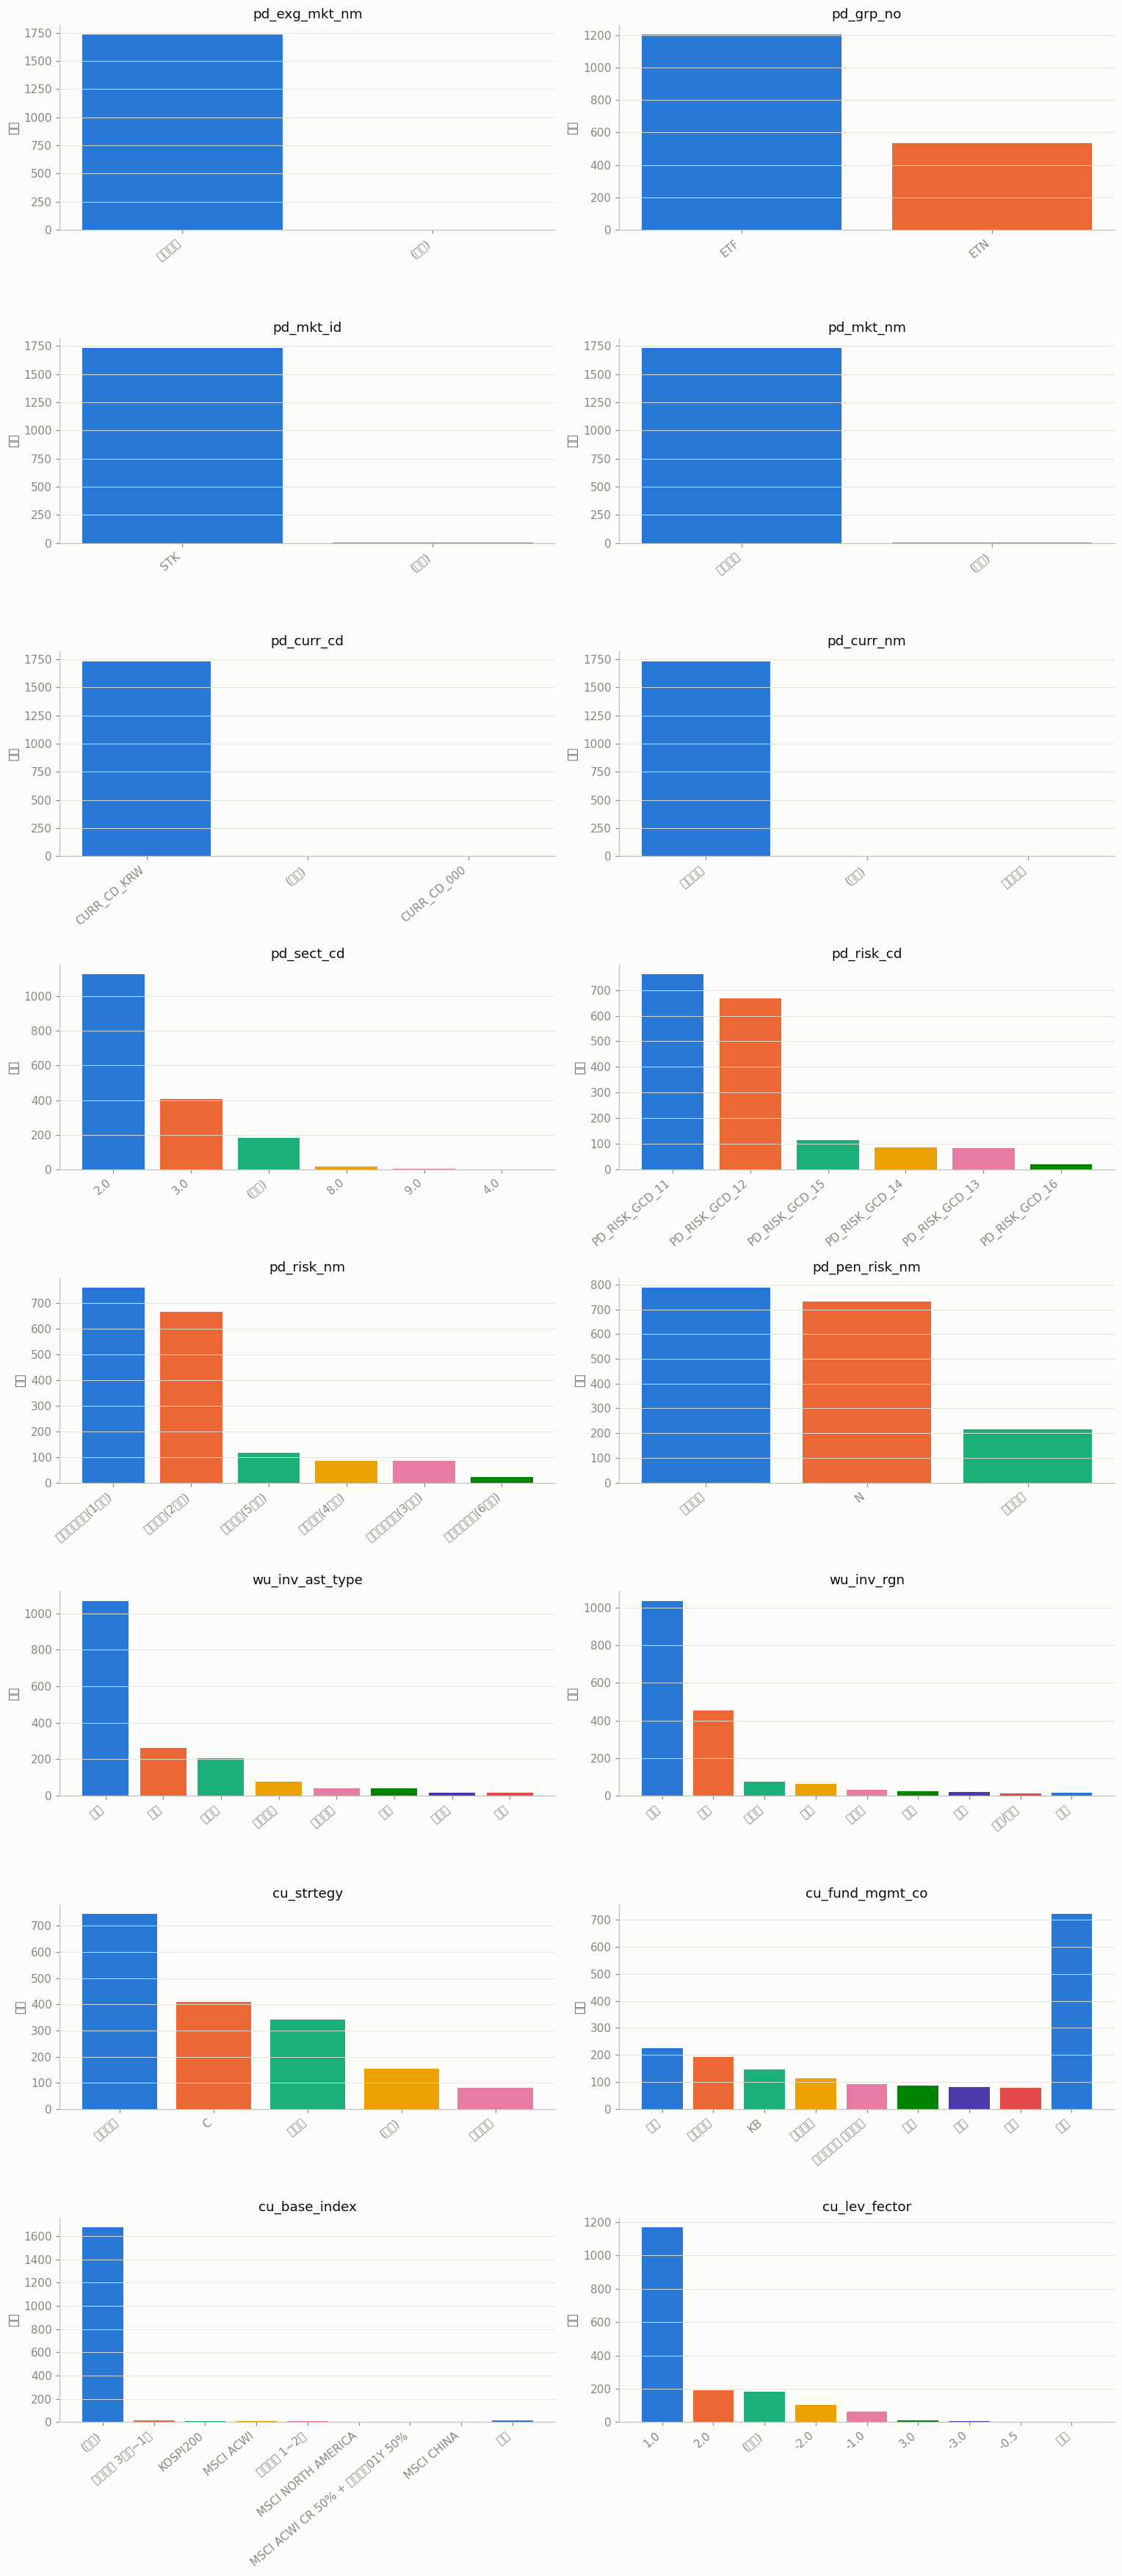

In [16]:
def plot_top_categories(col, top_n=8, ax=None):
    vc = df[col].fillna("(결측)").astype(str).value_counts()
    top = vc.head(top_n)
    if len(vc) > top_n:
        other = pd.Series({"기타": vc.iloc[top_n:].sum()})
        top = pd.concat([top, other])

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(7, 4))
    colors = cat_colors(len(top))
    ax.bar([str(x) for x in top.index], top.values, color=colors)
    ax.set_title(col)
    ax.set_ylabel("건수")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    if own_ax:
        plt.tight_layout()
        plt.show()


n_cols = 2
n_rows = int(np.ceil(len(CATEGORY_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, CATEGORY_COLS):
    plot_top_categories(col, ax=ax)
for ax in axes[len(CATEGORY_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. Y/N 플래그 컬럼 분석

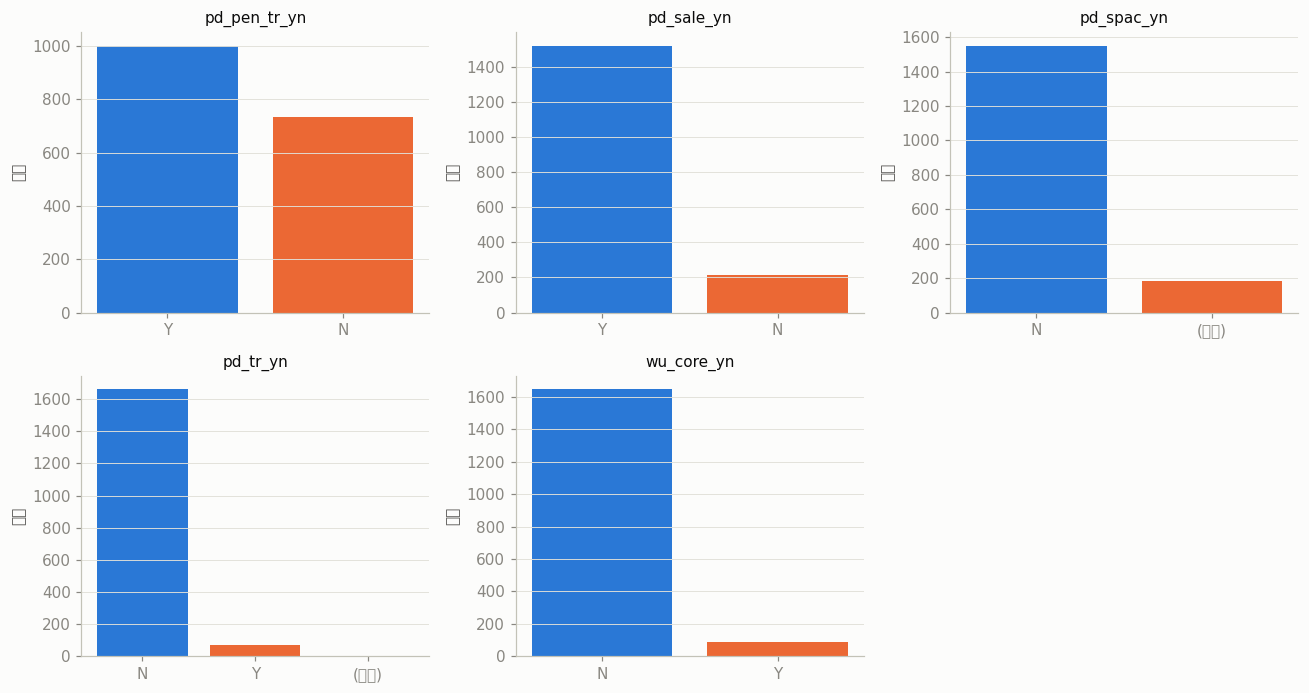

In [17]:
def normalize_flag(s: pd.Series) -> pd.Series:
    mapping = {
        "Y": "Y", "y": "Y", "1": "Y", 1: "Y", 1.0: "Y", True: "Y",
        "N": "N", "n": "N", "0": "N", 0: "N", 0.0: "N", False: "N",
    }
    return s.map(lambda v: mapping.get(v, v))


if FLAG_COLS:
    n_cols = 3
    n_rows = int(np.ceil(len(FLAG_COLS) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, FLAG_COLS):
        vc = normalize_flag(df[col]).fillna("(결측)").astype(str).value_counts()
        ax.bar([str(x) for x in vc.index], vc.values, color=cat_colors(len(vc)))
        ax.set_title(col, fontsize=10)
        ax.set_ylabel("건수")
    for ax in axes[len(FLAG_COLS):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 12. 수치형 변수 기술통계

In [18]:
stats = df[NUMERIC_COLS].describe().T
stats["skew"] = df[NUMERIC_COLS].skew()
stats["kurtosis"] = df[NUMERIC_COLS].kurtosis()
stats.sort_values("skew", ascending=False)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
du_vol_1d,"1,729.0000","4,464,948.1105","147,494,001.4478",0.0000,178.0000,"9,304.0000","101,904.0000","6,109,020,945.0000",41.1026,"1,701.1380"
du_vol_avg_5d,"1,729.0000","6,456,871.5452","216,999,382.6750",0.0000,526.2000,"10,640.4000","103,239.4000","8,983,542,191.8000",41.0508,"1,697.9853"
du_vol_avg_1m,"1,696.0000","6,689,371.6120","227,742,149.5290",0.0000,881.7875,"14,421.7000","127,750.6625","9,342,240,793.3000",40.7117,"1,668.7734"
pd_lst_stk_cnt,"1,734.0000","21,808,896.9435","289,812,828.5268",0.0000,"1,000,000.0000","2,000,000.0000","6,600,000.0000","11,410,900,000.0000",36.0258,"1,388.8033"
pd_stk_cnt,"1,551.0000","23,205,427.5951","302,736,401.7389","48,000.0000","1,000,000.0000","2,000,000.0000","7,910,000.0000","11,287,100,000.0000",34.2114,"1,248.3341"
du_val_1m,"1,694.0000","16,334,452,091.6807","123,928,206,970.1093",0.0000,"16,708,262.1500","252,049,318.1000","2,353,328,034.9000","3,068,646,617,382.6499",17.7198,386.4025
du_val_1d,"1,729.0000","16,069,002,058.7195","123,502,548,485.5199",0.0000,"3,183,170.0000","165,655,372.0000","1,914,765,632.0000","2,954,894,832,243.0000",15.5358,293.8970
pd_circ_net_tamt,"1,551.0000","159,539,129,318.5042","853,147,846,958.3817",0.0000,0.0000,0.0000,"34,344,485,000.0000","19,029,494,000,000.0000",13.5495,235.6089
du_val_5d,"1,729.0000","18,105,970,883.1012","136,034,411,587.9900",0.0000,"10,579,963.0000","199,445,123.0000","1,972,345,443.4000","2,649,650,947,844.6001",13.5489,215.6533
pd_circ_stk_cnt,"1,551.0000","13,081,904.0619","54,544,359.6756",0.0000,0.0000,"1,300,000.0000","6,450,000.0000","1,128,710,000.0000",12.5997,212.0155


## 13. 수치형 변수 분포 시각화

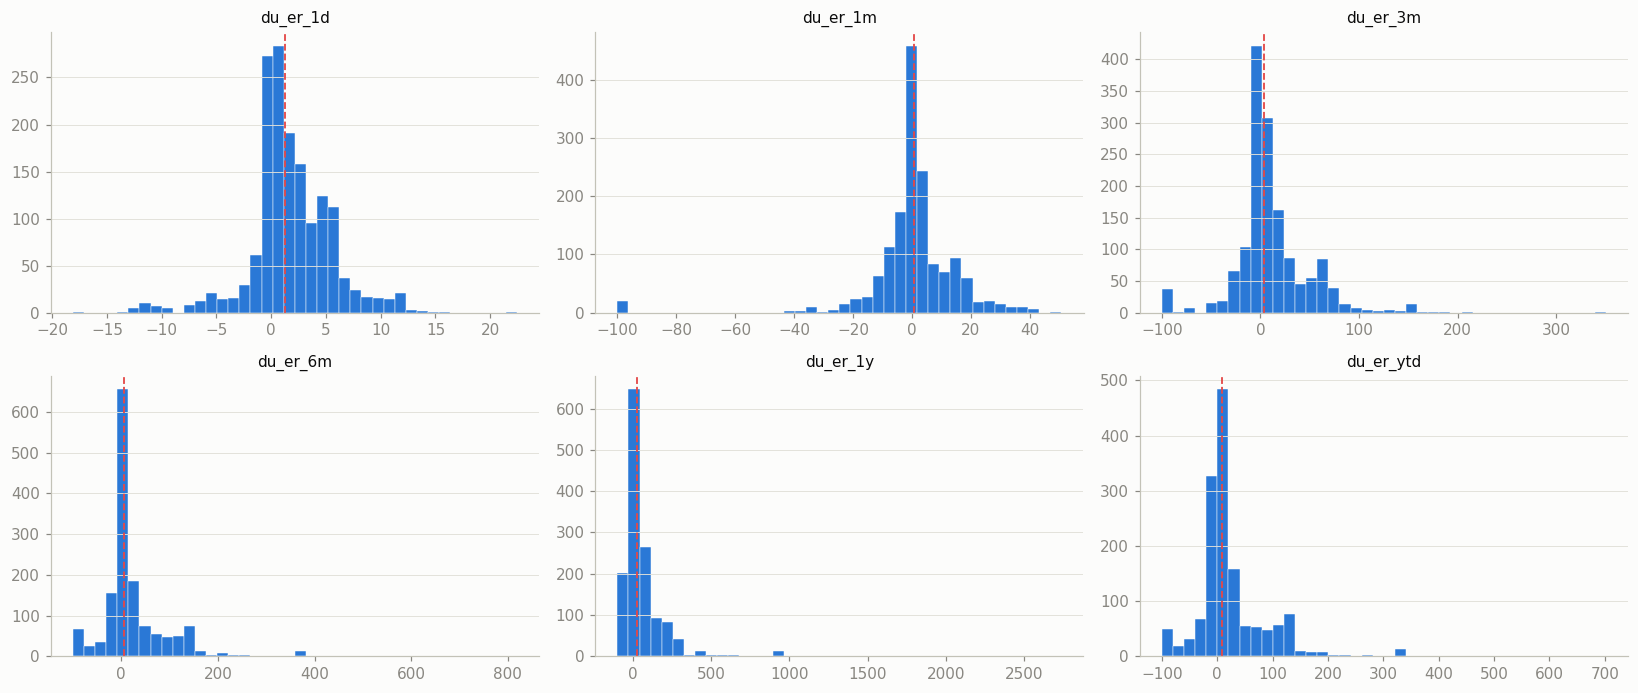

In [19]:
def plot_histograms(cols, n_cols=3, bins=40):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        return
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cols):
        data = df[col].dropna()
        ax.hist(data, bins=bins, color=CAT_COLORS[0], edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
        ax.axvline(data.median(), color=CAT_COLORS[7], linewidth=1.2, linestyle="--", label="median")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_histograms(RETURN_COLS)


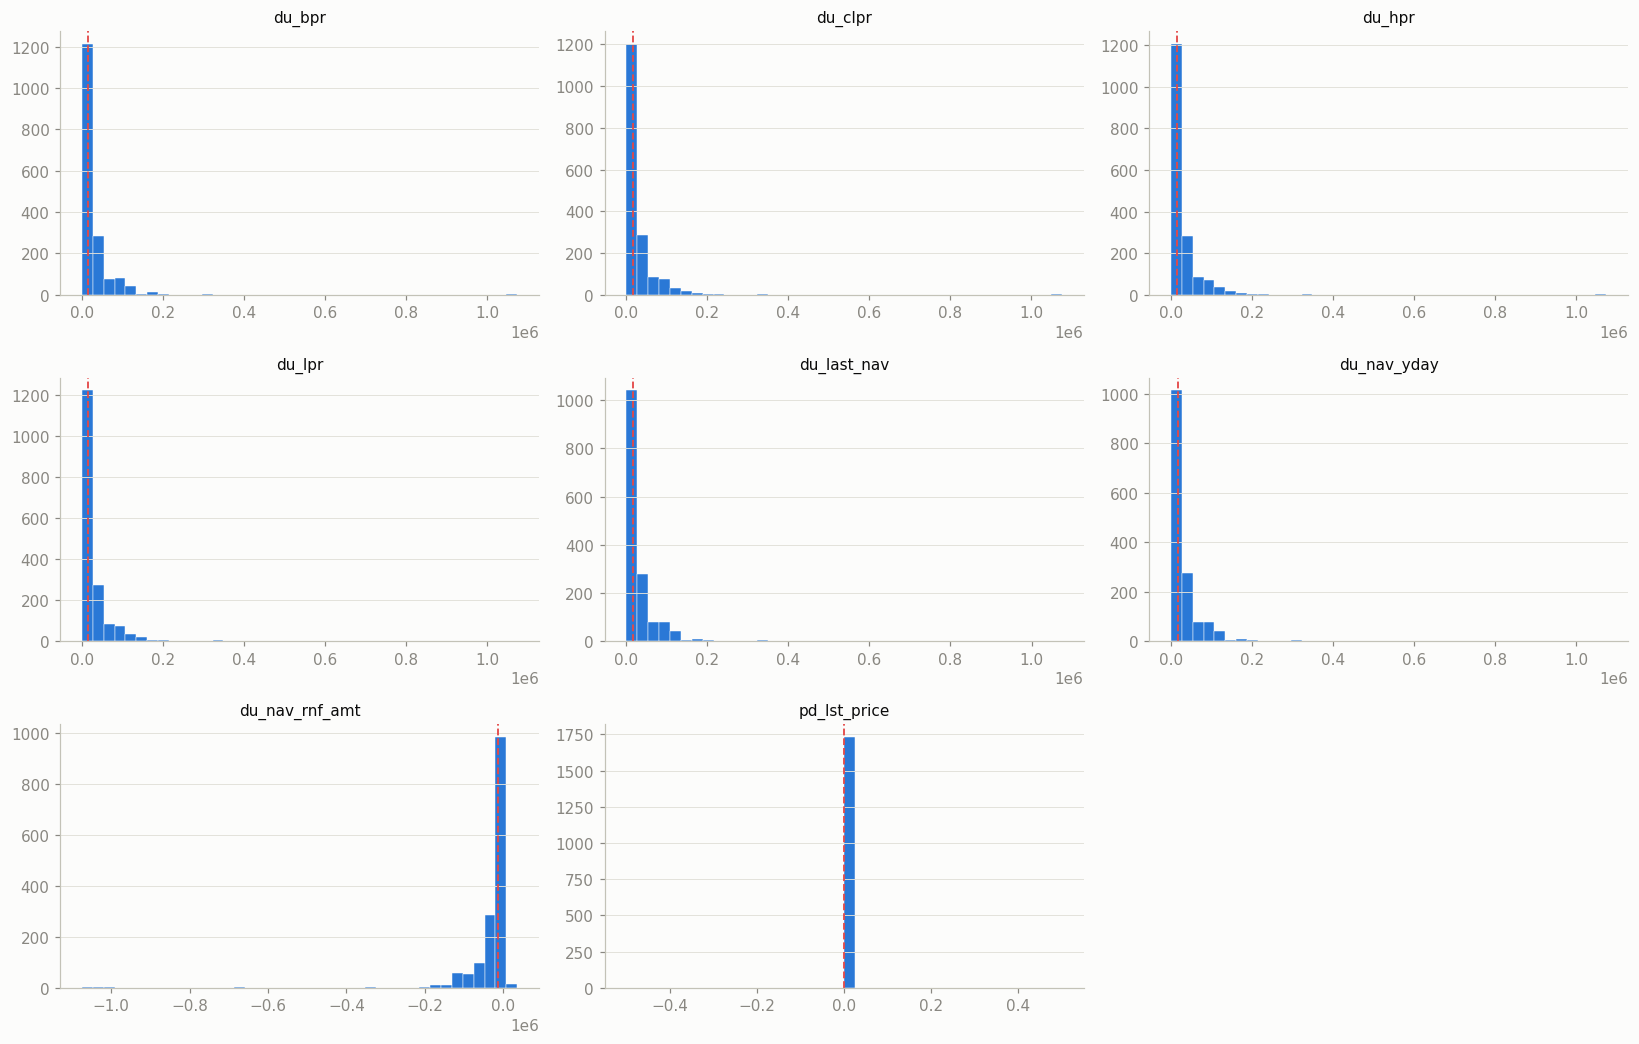

In [20]:
plot_histograms(PRICE_COLS)


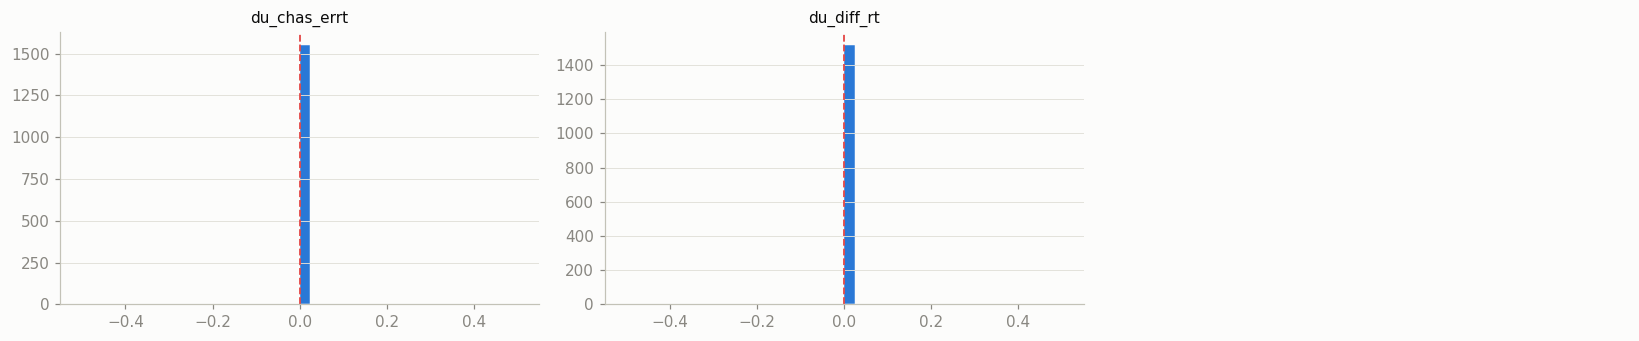

In [21]:
plot_histograms(TRACKING_COLS)


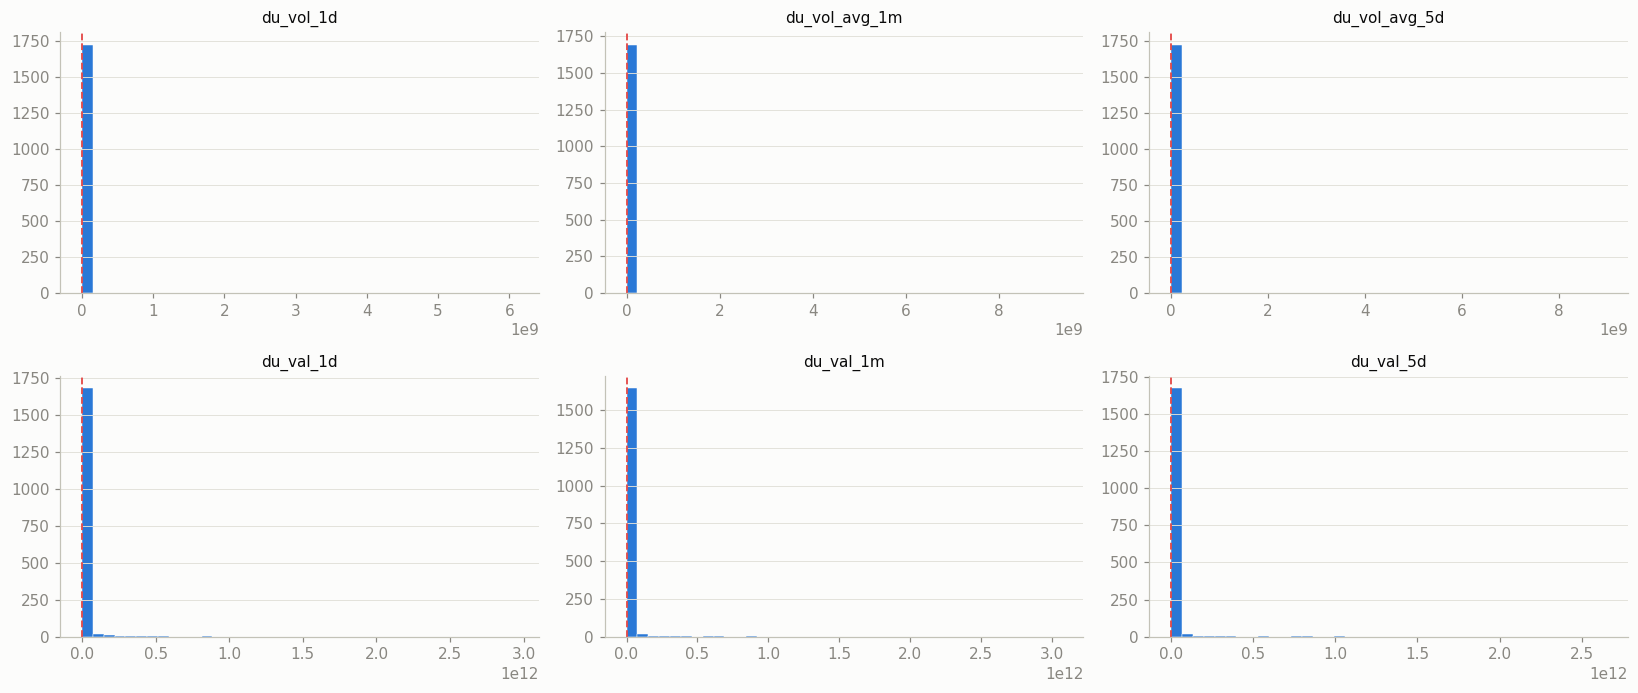

In [22]:
plot_histograms(VOLUME_COLS)


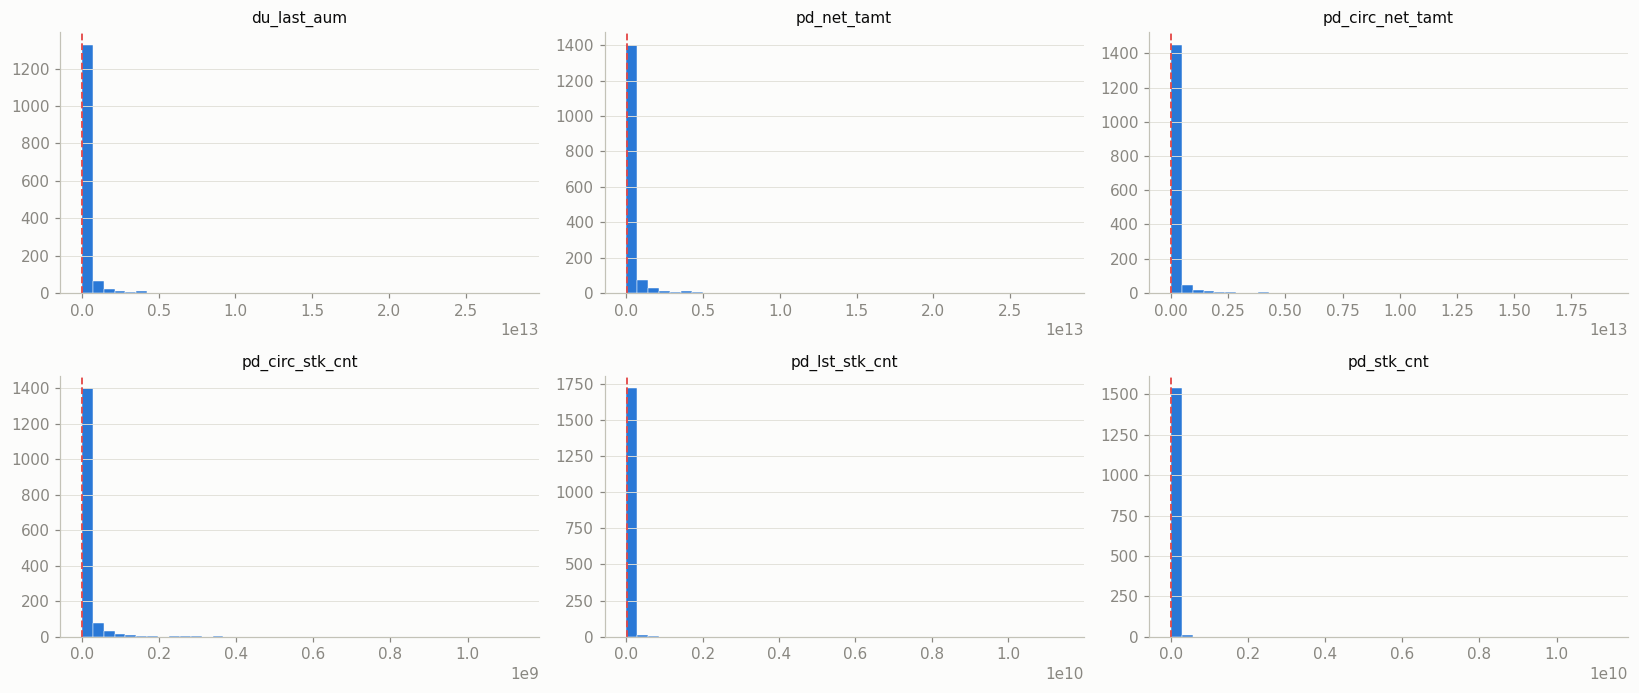

In [23]:
plot_histograms(SIZE_COLS)


## 14. 이상치 탐지 (IQR 기준)

In [24]:
def iqr_outlier_summary(cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({
            "column": col, "q1": q1, "q3": q3, "iqr": iqr,
            "lower": lo, "upper": hi,
            "n_outliers": n_out, "pct_outliers": round(n_out / len(s) * 100, 2),
        })
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)


outlier_summary = iqr_outlier_summary(NUMERIC_COLS)
outlier_summary


,column,q1,q3,iqr,lower,upper,n_outliers,pct_outliers
11,du_er_6m,-3.1100,34.0350,37.1450,-58.8275,89.7525,283,19.1700
13,du_er_ytd,-2.4300,35.8300,38.2600,-59.8200,93.2200,264,17.8700
18,du_vol_avg_5d,526.2000,"103,239.4000","102,713.2000","-153,543.6000","257,309.2000",299,17.2900
24,pd_circ_net_tamt,0.0000,"34,344,485,000.0000","34,344,485,000.0000","-51,516,727,500.0000","85,861,212,500.0000",266,17.1500
16,du_vol_1d,178.0000,"101,904.0000","101,726.0000","-152,411.0000","254,493.0000",296,17.1200
17,du_vol_avg_1m,881.7875,"127,750.6625","126,868.8750","-189,421.5250","318,053.9750",290,17.1000
19,du_val_1d,"3,183,170.0000","1,914,765,632.0000","1,911,582,462.0000","-2,864,190,523.0000","4,782,139,325.0000",292,16.8900
20,du_val_1m,"16,708,262.1500","2,353,328,034.9000","2,336,619,772.7500","-3,488,221,396.9750","5,858,257,694.0250",284,16.7700
21,du_val_5d,"10,579,963.0000","1,972,345,443.4000","1,961,765,480.4000","-2,932,068,257.6000","4,914,993,664.0000",288,16.6600
10,du_er_3m,-2.2900,22.5000,24.7900,-39.4750,59.6850,232,15.4200


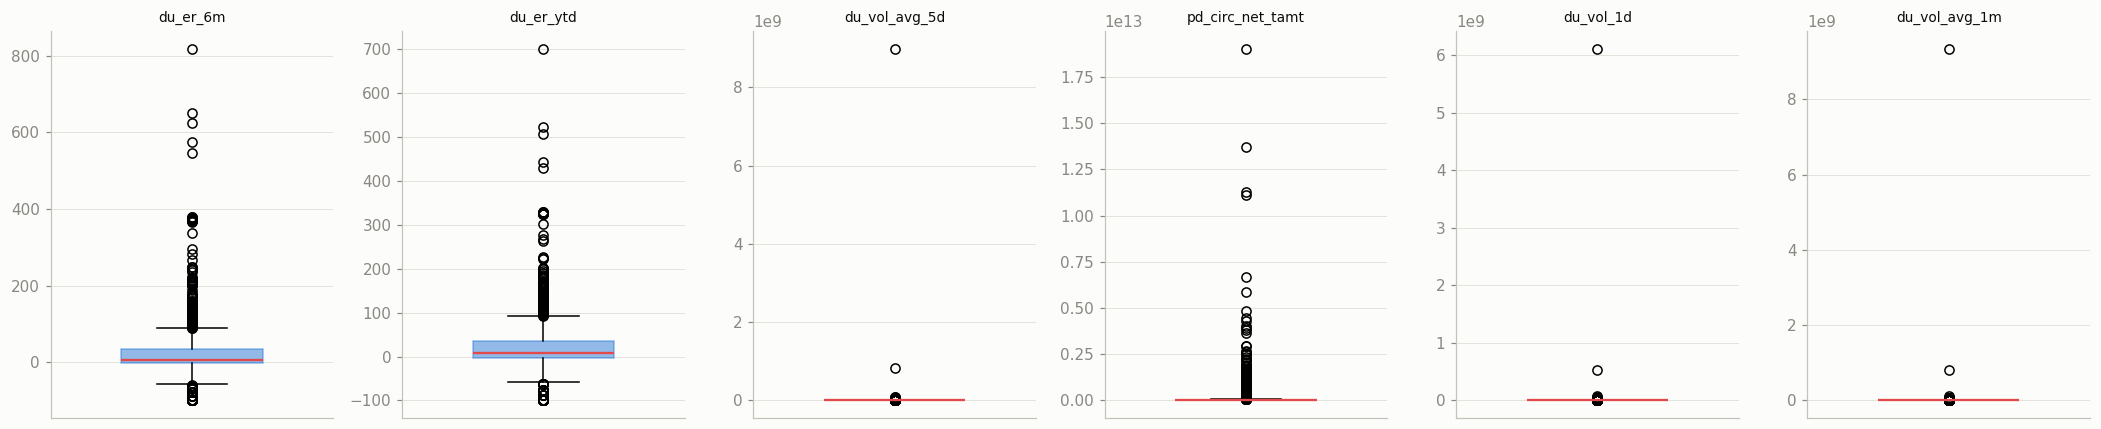

In [25]:
top_outlier_cols = outlier_summary.head(6)["column"].tolist()
if top_outlier_cols:
    fig, axes = plt.subplots(1, len(top_outlier_cols), figsize=(3.2 * len(top_outlier_cols), 4))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, top_outlier_cols):
        bp = ax.boxplot(df[col].dropna(), patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title(col, fontsize=9)
        ax.set_xticks([])
    plt.tight_layout()
    plt.show()


## 15. 순자산(AUM) 분석

`du_last_aum`(최종AUM)과 `pd_net_tamt`(순자산총액) 두 컬럼이 개념적으로 같은 값을 가리킬 가능성이 있어 함께 비교합니다.

du_last_aum vs pd_net_tamt 상대 차이 5% 초과 종목: 439 / 1,453건


,pd_itm_no,pd_abrv_nm,cu_fund_mgmt_co,wu_inv_ast_type,du_last_aum
977,KR7069500007,KODEX 200,삼성,주식,"28,359,162,742,500.0000"
770,KR7360750004,TIGER 미국S&P500,미래에셋,주식,"19,033,336,756,500.0000"
1238,KR7396500001,TIGER 반도체TOP10,미래에셋,주식,"13,793,920,162,500.0000"
322,KR7102110004,TIGER 200,미래에셋,주식,"11,317,568,103,500.0000"
191,KR7133690008,TIGER 미국나스닥100,미래에셋,주식,"11,141,723,622,000.0000"
222,KR7379800006,KODEX 미국S&P500,삼성,주식,"9,825,340,534,500.0000"
143,KR7122630007,KODEX 레버리지,삼성KODEX레버리지증권상장지수투자신탁[주식-파생형],주식,"9,619,402,275,000.0000"
158,KR7278530001,KODEX 200TR,삼성,주식,"8,930,466,306,000.0000"
37,KR7379810005,KODEX 미국나스닥100,삼성,주식,"8,617,313,520,000.0000"
1466,KR7488770009,KODEX 머니마켓액티브,삼성,채권,"8,113,584,619,350.0000"


,count,sum,mean
cu_fund_mgmt_co,,,
삼성,196,"165,657,624,244,684.0000","845,191,960,432.0613"
미래에셋,172,"130,970,853,989,502.0000","761,458,453,427.3372"
KB,127,"34,218,326,348,680.0000","269,435,640,540.7874"
한국투자,105,"26,789,387,731,300.0000","255,137,026,012.3810"
신한,67,"22,339,229,911,710.0000","333,421,341,965.8209"
한화,76,"12,318,351,117,600.0000","162,083,567,336.8421"
삼성KODEX레버리지증권상장지수투자신탁[주식-파생형],1,"9,619,402,275,000.0000","9,619,402,275,000.0000"
NH-Amundi,46,"8,258,946,563,240.0000","179,542,316,592.1739"
타임폴리오,18,"8,088,057,352,300.0000","449,336,519,572.2222"


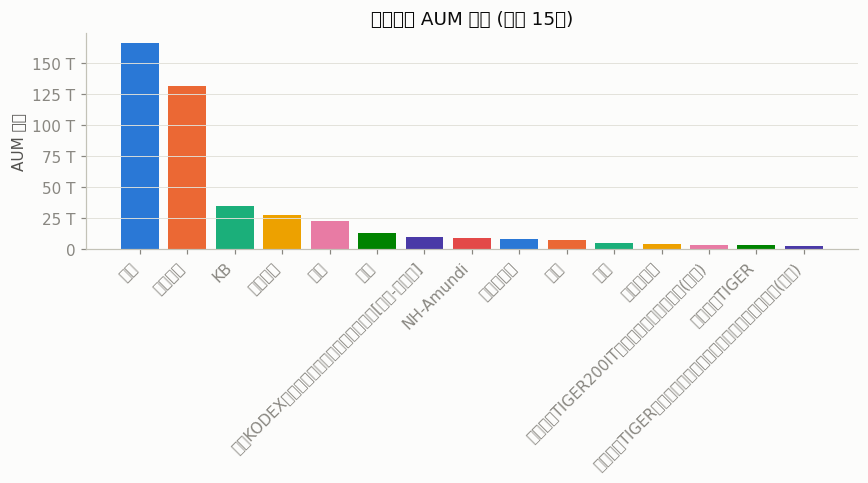

In [26]:
if {"du_last_aum", "pd_net_tamt"}.issubset(df.columns):
    aum_diff = (df["du_last_aum"] - df["pd_net_tamt"]).abs()
    rel_diff = (aum_diff / df["pd_net_tamt"].replace(0, np.nan)).abs()
    print(f"du_last_aum vs pd_net_tamt 상대 차이 5% 초과 종목: {(rel_diff > 0.05).sum():,} / {rel_diff.notna().sum():,}건")

if "du_last_aum" in df.columns:
    top_funds = df.nlargest(20, "du_last_aum")[
        [c for c in ["pd_itm_no", "pd_abrv_nm", "cu_fund_mgmt_co", "wu_inv_ast_type", "du_last_aum"] if c in df.columns]
    ]
    display(top_funds)

    if "cu_fund_mgmt_co" in df.columns:
        by_co = (
            df.groupby("cu_fund_mgmt_co")["du_last_aum"]
            .agg(["count", "sum", "mean"])
            .sort_values("sum", ascending=False)
            .head(15)
        )
        display(by_co)

        fig, ax = plt.subplots(figsize=(8, 4.5))
        colors = cat_colors(len(by_co))
        ax.bar([str(x) for x in by_co.index], by_co["sum"], color=colors)
        ax.set_title("운용사별 AUM 합계 (상위 15개)")
        ax.set_ylabel("AUM 합계")
        ax.tick_params(axis="x", rotation=45)
        for label in ax.get_xticklabels():
            label.set_ha("right")
        ax.yaxis.set_major_formatter(mticker.EngFormatter())
        plt.tight_layout()
        plt.show()


## 16. 추적오차·괴리율 분석 (ETF 핵심 지표)

추적오차율(`du_chas_errt`)과 괴리율(`du_diff_rt`, `nru_mkt_diff_rt`)은 ETF가 기초지수/NAV를 얼마나 잘 따라가는지를 보여주는 핵심 품질 지표입니다.

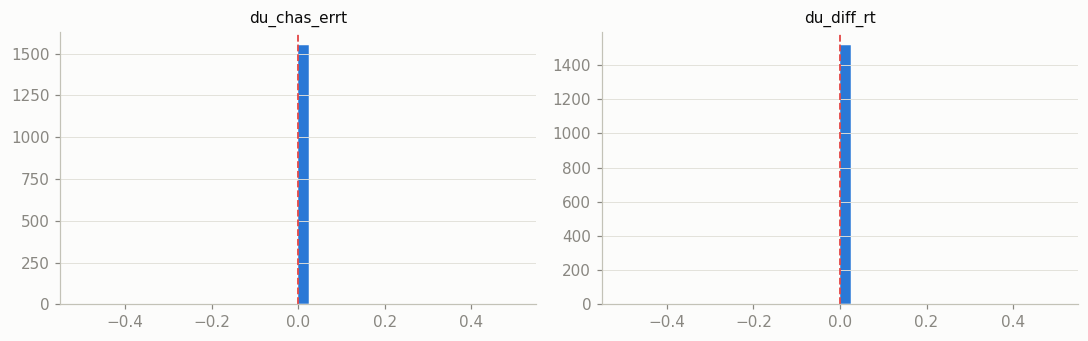

,pd_itm_no,pd_abrv_nm,du_diff_rt,du_chas_errt,cu_fund_mgmt_co
0,KR7305080004,TIGER 미국채10년선물,0.0000,0.0000,미래에셋
1154,KR7487950008,KODEX 대만테크고배당다우존스,0.0000,0.0000,삼성
1164,KR7460960008,ACE 글로벌인컴TOP10,0.0000,0.0000,한국투자
1163,KR7228790002,TIGER 화장품,0.0000,0.0000,미래에셋
1162,KRG580000757,KB 레버리지 BYD 밸류체인 ETN,0.0000,0.0000,KB증권(주)
1161,KR7139280002,TIGER 경기방어,0.0000,0.0000,미래에셋
1160,KR70191B0000,MIDAS 코스닥액티브,0.0000,0.0000,마이다스
1159,KR7252670005,KODEX 200선물인버스2X,0.0000,0.0000,삼성
1158,KR70068M0007,KODEX 미국S&P500버퍼6월액티브,0.0000,0.0000,삼성
1156,KR70038A0008,KODEX 미국휴머노이드로봇,0.0000,0.0000,삼성


In [27]:
plot_histograms(TRACKING_COLS, n_cols=2)

if "du_diff_rt" in df.columns:
    extreme = df.reindex(df["du_diff_rt"].abs().sort_values(ascending=False).index).head(10)
    display(extreme[[c for c in ["pd_itm_no", "pd_abrv_nm", "du_diff_rt", "du_chas_errt", "cu_fund_mgmt_co"] if c in df.columns]])


## 17. 상품등급(pd_risk_nm)별 수익률 분포

,count
pd_risk_nm,
매우높은위험(1등급),761
높은위험(2등급),667
낮은위험(5등급),115
보통위험(4등급),86
다소높은위험(3등급),84
매우낮은위험(6등급),21


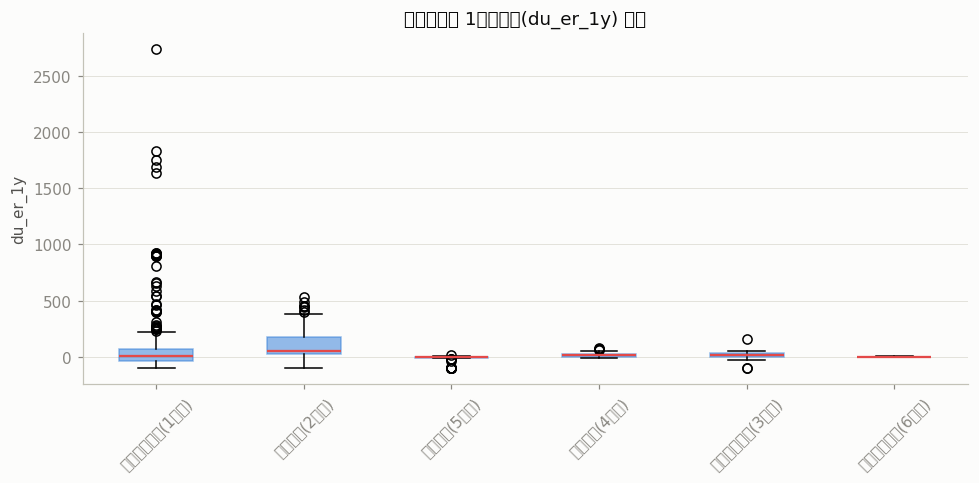

In [28]:
if "pd_risk_nm" in df.columns:
    risk_filled = df["pd_risk_nm"].fillna("(결측)").astype(str)
    grade_counts = risk_filled.value_counts()
    display(grade_counts.to_frame("count"))

    if "du_er_1y" in df.columns:
        order = grade_counts.index.tolist()
        fig, ax = plt.subplots(figsize=(9, 4.5))
        data_by_grade = [df.loc[risk_filled == g, "du_er_1y"].dropna() for g in order]
        bp = ax.boxplot(data_by_grade, labels=[str(g) for g in order], patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title("상품등급별 1년수익률(du_er_1y) 분포")
        ax.set_ylabel("du_er_1y")
        ax.tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()


## 18. 기간별 수익률 상관관계

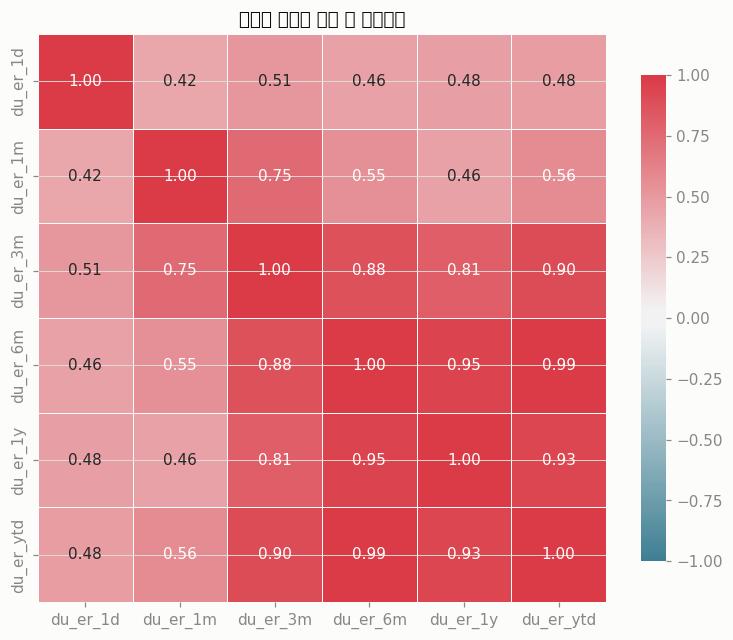

In [29]:
return_corr = df[RETURN_COLS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    return_corr, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor=SURFACE,
    cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("기간별 수익률 컬럼 간 상관관계")
plt.tight_layout()
plt.show()


## 19. 거래량 vs 순자산 규모 산점도

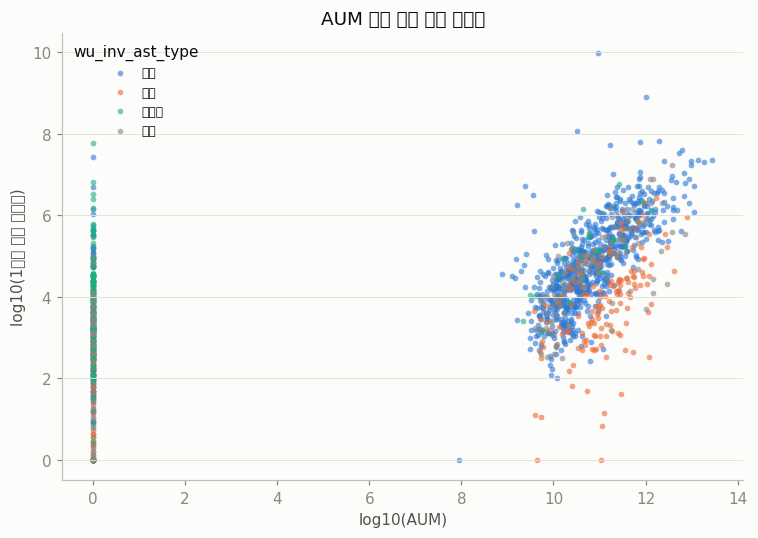

In [30]:
if {"du_vol_avg_1m", "du_last_aum"}.issubset(df.columns):
    hue_col = "wu_inv_ast_type" if "wu_inv_ast_type" in df.columns else None

    fig, ax = plt.subplots(figsize=(7, 5))
    x_log = np.log10(df["du_last_aum"].clip(lower=1))
    y_log = np.log10(df["du_vol_avg_1m"].clip(lower=1))

    if hue_col:
        top_cats = df[hue_col].value_counts().head(3).index.tolist()
        plot_df = df.copy()
        plot_df["_x_log"] = x_log
        plot_df["_y_log"] = y_log
        plot_df[hue_col] = plot_df[hue_col].where(plot_df[hue_col].isin(top_cats), "기타")
        cats = top_cats + (["기타"] if plot_df[hue_col].eq("기타").any() else [])
        colors = CAT_COLORS[:len(top_cats)] + ([INK_MUTED] if "기타" in cats else [])
        for cat, color in zip(cats, colors):
            sub = plot_df[plot_df[hue_col] == cat]
            ax.scatter(sub["_x_log"], sub["_y_log"], s=14, alpha=0.6, color=color, label=str(cat), linewidths=0)
        ax.legend(title=hue_col, frameon=False, fontsize=8)
    else:
        ax.scatter(x_log, y_log, s=14, alpha=0.5, color=CAT_COLORS[0], linewidths=0)

    ax.set_xlabel("log10(AUM)")
    ax.set_ylabel("log10(1개월 평균 거래량)")
    ax.set_title("AUM 규모 대비 거래 활발도")
    plt.tight_layout()
    plt.show()


## 20. 수치형 변수 전체 상관관계

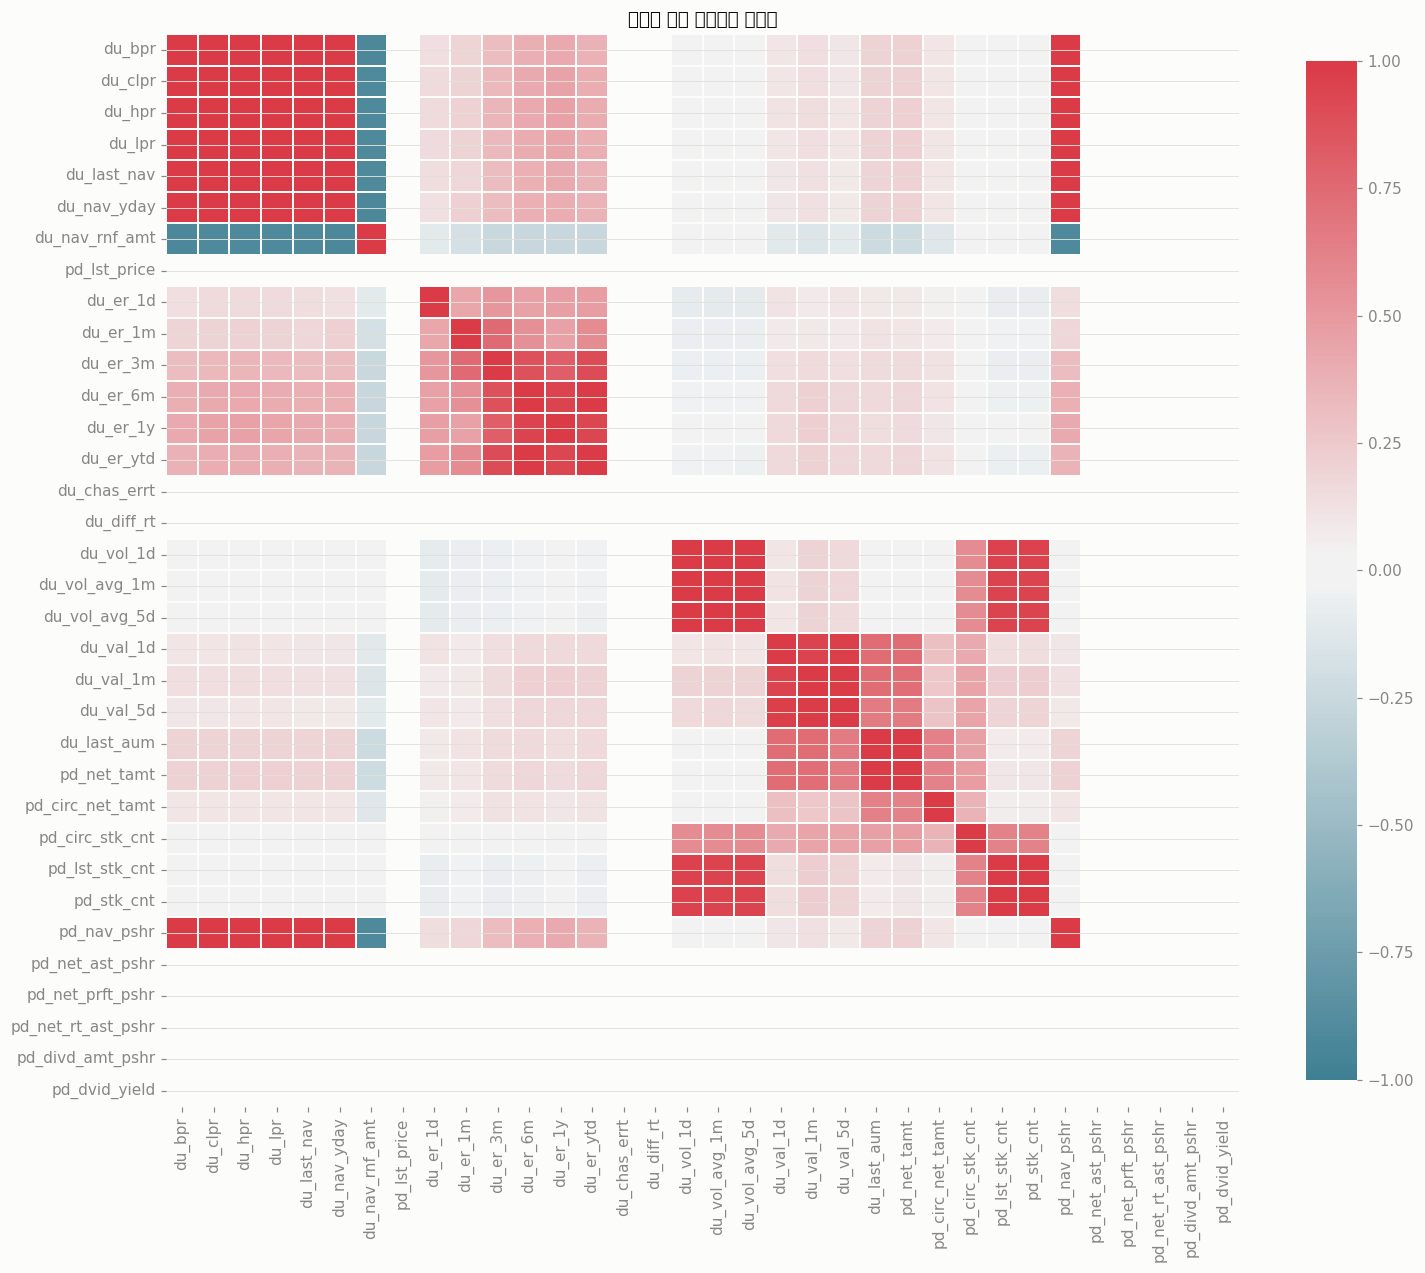

In [31]:
corr = df[NUMERIC_COLS].corr()
fig, ax = plt.subplots(figsize=(0.35 * len(NUMERIC_COLS) + 2, 0.35 * len(NUMERIC_COLS) + 2))
sns.heatmap(
    corr, cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.3, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax,
)
ax.set_title("수치형 변수 상관관계 히트맵")
plt.tight_layout()
plt.show()


In [32]:
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .to_frame()
    .assign(abs_corr=lambda x: x["corr"].abs())
    .sort_values("abs_corr", ascending=False)
)
corr_pairs.head(20)


corr  abs_corr
du_last_nav    pd_nav_pshr   1.0000    1.0000
pd_lst_stk_cnt pd_stk_cnt    1.0000    1.0000
du_vol_avg_1m  du_vol_avg_5d 1.0000    1.0000
du_bpr         du_nav_yday   1.0000    1.0000
du_vol_1d      du_vol_avg_5d 0.9999    0.9999
               du_vol_avg_1m 0.9999    0.9999
du_hpr         du_lpr        0.9996    0.9996
du_last_nav    du_nav_yday   0.9994    0.9994
du_nav_yday    pd_nav_pshr   0.9994    0.9994
du_lpr         du_nav_yday   0.9993    0.9993
du_bpr         du_last_nav   0.9990    0.9990
               pd_nav_pshr   0.9990    0.9990
               du_clpr       0.9988    0.9988
du_clpr        du_nav_yday   0.9988    0.9988
               du_last_nav   0.9986    0.9986
               pd_nav_pshr   0.9986    0.9986
du_hpr         du_nav_yday   0.9983    0.9983
du_lpr         du_last_nav   0.9982    0.9982
               pd_nav_pshr   0.9982    0.9982
du_clpr        du_hpr        0.9980    0.9980

## 21. 운용사(cu_fund_mgmt_co)별 요약

In [33]:
if "cu_fund_mgmt_co" in df.columns:
    agg_dict = {"pd_itm_no": "count"}
    for c in ["du_last_aum", "du_er_1y", "du_chas_errt", "du_vol_avg_1m"]:
        if c in df.columns:
            agg_dict[c] = "sum" if c == "du_last_aum" else "mean"

    summary_by_co = df.groupby("cu_fund_mgmt_co").agg(agg_dict).rename(columns={"pd_itm_no": "종목수"})
    summary_by_co.sort_values("종목수", ascending=False)


## 22. 갱신주기(접두사)별 결측 패턴 비교

컬럼명 접두사(`pd_`/`cu_`/`du_`/`wu_`/`nru_`/`ru_`)별로 평균 결측률을 비교합니다.
실시간/준실시간 갱신 컬럼(`ru_`, `nru_`)은 장 마감 후 추출 시점에 따라 결측률이 유독 높게 나올 수 있습니다 — raw 데이터 추출 시각을 함께 확인해보세요.

In [34]:
prefix_map = {}
for col in df.columns:
    for prefix in ["pd_", "cu_", "du_", "wu_", "nru_", "ru_"]:
        if col.startswith(prefix):
            prefix_map.setdefault(prefix, []).append(col)
            break

prefix_missing = {
    prefix: df[cols].isna().mean().mean() * 100
    for prefix, cols in prefix_map.items()
}
pd.Series(prefix_missing, name="평균 결측률(%)").sort_values(ascending=False).to_frame()


,평균 결측률(%)
cu_,33.3160
du_,7.9705
pd_,6.4953
wu_,0.1153
